In [1]:
import pandas as pd
import numpy as np
df = pd.read_csv(r"C:\Users\Dell\Documents\Intro to AI - LABWorks\LAB 4\diabetes.csv")
df.head(5)

,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


In [2]:
from sklearn.model_selection import train_test_split
X=df[['Glucose','BloodPressure','SkinThickness','Insulin','BMI','DiabetesPedigreeFunction','Age']]
y=df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42)

In [3]:
X_test


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
668,98,58.0,33,190.0,34.0,0.430,43
324,112,75.0,32,102.5,35.7,0.148,21
624,108,64.0,27,102.5,30.8,0.158,21
690,107,80.0,27,102.5,24.6,0.856,34
473,136,90.0,27,102.5,29.9,0.210,50
...,...,...,...,...,...,...,...
355,165,88.0,32,169.5,30.4,0.302,49
534,77,56.0,30,56.0,33.3,1.251,24
344,95,72.0,27,102.5,36.8,0.485,57
296,146,70.0,38,360.0,28.0,0.337,29


In [4]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](7,)","[ 0.01,-0. , 0.01,..., 0.01, 0.07, 0.01]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](7,)","['Glucose','BloodPressure','SkinThickness',...,'BMI', 'DiabetesPedigreeFunction','Age']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-1.07
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int,7


In [6]:
print(model.coef_)

[ 0.00535886 -0.00122673  0.00598341  0.00057586  0.01042811  0.07358127
  0.00690012]


In [7]:
print(model.intercept_)

-1.069609192194591


In [8]:
y_predict = model.predict(X_test)
y_predict

array([ 3.74176082e-01,  2.17149726e-01,  1.28929321e-01,  1.80349787e-01,
        4.41626847e-01,  4.91398591e-01, -2.08243273e-01,  4.16737604e-01,
        5.19983281e-01,  6.59012241e-01,  2.71666912e-01,  8.00315188e-01,
        5.27944238e-01,  2.20797863e-01, -7.30382781e-05,  4.85661987e-01,
        1.43480910e-01,  2.35723979e-02,  6.68910843e-01,  4.72878722e-01,
        2.60305601e-01,  8.42303319e-02,  4.97507152e-01,  9.03637100e-02,
        4.30319786e-01,  7.87661481e-01,  1.23644650e-01, -1.18695222e-01,
        2.98528828e-01,  8.09967786e-02,  8.81078692e-01,  8.08229913e-01,
        8.32772641e-01,  6.28573438e-01,  5.02288481e-01,  6.01214711e-01,
        1.42215341e+00,  3.47695668e-01,  3.67081878e-01,  4.79852588e-01,
       -1.97833273e-02,  5.64959836e-01,  4.66690987e-01,  3.10242554e-01,
       -5.43189524e-02,  6.25697924e-01,  7.12891116e-01,  2.14304607e-01,
        3.70955269e-01,  1.07625635e+00, -4.15857770e-02,  6.36336004e-01,
        8.72321254e-01,  

In [9]:
results = pd.DataFrame({
    'YearsExperience': X_test['Y'].values,
    'Actual Salary': y_test.values,
    'Predicted Salary': y_predict
})
print(results)

KeyError: 'Y'

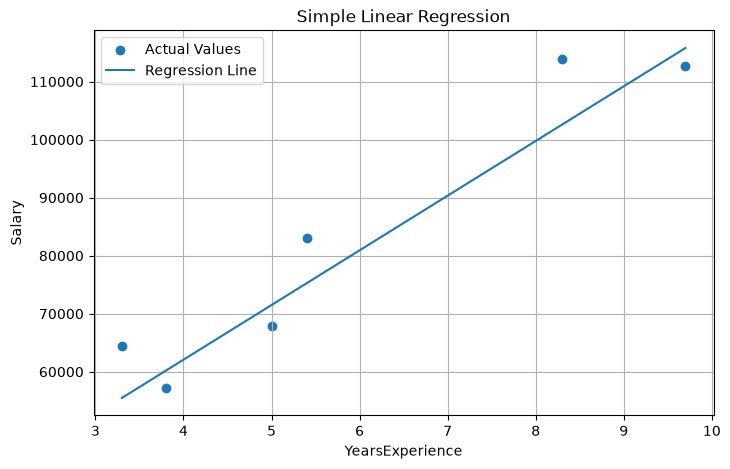

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test["YearsExperience"],
    y_test,
    label="Actual Values"
)

sorted_indices = np.argsort(X_test["YearsExperience"].values)

X_sorted = X_test["YearsExperience"].values[sorted_indices]
y_pred_sorted = y_predict[sorted_indices]

plt.plot(
    X_sorted,
    y_pred_sorted,
    label="Regression Line"
)

plt.title("Simple Linear Regression")
plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.legend()
plt.grid(True)

plt.show()